# 1990 — Recurrent Networks (Elman / "Simple RNN")

**Paper:** Jeffrey Elman, *"Finding Structure in Time"* (1990). (Jordan networks, 1986, are a close relative.)

Feed-forward nets see a fixed-size input. An RNN keeps a **hidden state** that is fed back at every step, giving it memory:

$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h), \qquad y_t = W_{hy} h_t + b_y$$

Training = **backpropagation through time** (BPTT): unroll the loop and backprop through the unrolled graph.

Elman trained his network to **predict the next letter** in a stream and found that prediction error peaks at word boundaries — the network discovered "words" without being told. We reproduce that here with a character-level RNN written by hand.

![Diagram: Elman network (1990)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/11_1990_elman_rnn.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A small original corpus (written for this repo) so the notebook runs offline.
CORPUS = """In the beginning a neuron was only a switch. It added up its inputs, compared the sum with a threshold, and fired or stayed silent. Logicians showed that networks of such switches could compute anything a machine could compute, but nobody knew how to choose the connections.
The perceptron answered part of that question. It changed its weights a little every time it made a mistake, and if the classes could be split by a straight line, it was guaranteed to find one. Critics then pointed out that a single layer could not even learn exclusive or, and the field grew quiet for many years.
Backpropagation brought it back. By sending errors backwards through the chain rule, a network with hidden layers could learn its own features. Convolutional networks learned to read handwritten digits, and recurrent networks learned to carry information through time. The long short term memory added gates so that gradients could survive across many steps.
Then data grew large and graphics cards grew fast. A deep convolutional network won an image contest by a wide margin, and suddenly every lab wanted deeper models. Residual connections let networks grow to hundreds of layers. Normalization kept the signals steady. Generative models learned to dream new images from noise.
Attention changed everything again. Instead of reading a sentence one word at a time, a transformer lets every word look at every other word at once. Stack enough of these layers, feed them enough text, and they learn grammar, facts, and a surprising amount of reasoning. Scaling the data and the parameters together turned out to be a reliable recipe.
Today the frontier mixes many ideas. Mixtures of experts activate only a few parameters per token. Linear recurrent layers with gated memory handle very long contexts cheaply. Diffusion and flow models paint images, sound, and video. Reinforcement learning with verifiable rewards teaches models to think before they answer. Yet every one of these systems is still built from the same humble part: a weighted sum followed by a simple nonlinearity.
"""
print(f"corpus: {len(CORPUS):,} characters")
text = CORPUS.lower()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
V = len(chars)
print("vocab size:", V)

corpus: 2,073 characters
vocab size: 30


step    0 loss 3.464


step  300 loss 0.293


step  600 loss 0.167


step  900 loss 0.167


step 1200 loss 0.146


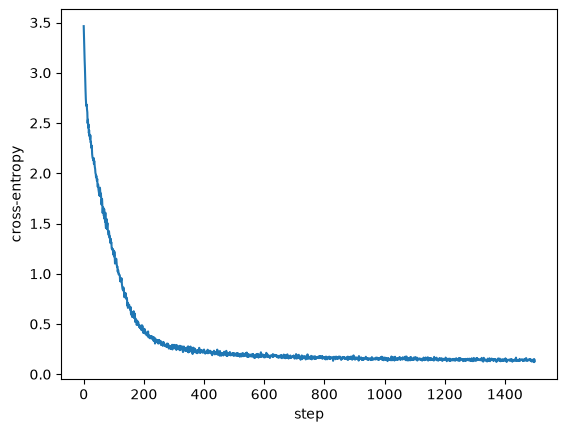

In [3]:
class ElmanRNN(nn.Module):
    def __init__(self, vocab, hidden):
        super().__init__()
        self.hidden = hidden
        self.embed = nn.Embedding(vocab, hidden)          # = W_xh applied to a one-hot input
        self.W_hh = nn.Linear(hidden, hidden)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, x, h=None):
        B, T = x.shape
        h = torch.zeros(B, self.hidden, device=x.device) if h is None else h
        e = self.embed(x)
        outs = []
        for t in range(T):                                 # the recurrence, written out explicitly
            h = torch.tanh(e[:, t] + self.W_hh(h))
            outs.append(h)
        H = torch.stack(outs, 1)
        return self.out(H), h

model = ElmanRNN(V, 128).to(device)
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
T, B = 48, 32
losses = []
for step in range(1500):
    ix = torch.randint(0, len(data) - T - 1, (B,), device=device)
    x = data[ix[:, None] + torch.arange(T, device=data.device)]; y = data[ix[:, None] + torch.arange(1, T + 1, device=data.device)]
    logits, _ = model(x)
    loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # tames exploding gradients in BPTT
    opt.step(); losses.append(loss.item())
    if step % 300 == 0: print(f"step {step:4d} loss {loss.item():.3f}")
plt.plot(losses); plt.xlabel("step"); plt.ylabel("cross-entropy"); plt.show()

## Elman's observation: surprise peaks at word boundaries
Per-character prediction error (−log p of the true next character) along a sentence. The first letter of each word is hard to predict; the rest of the word is easy.

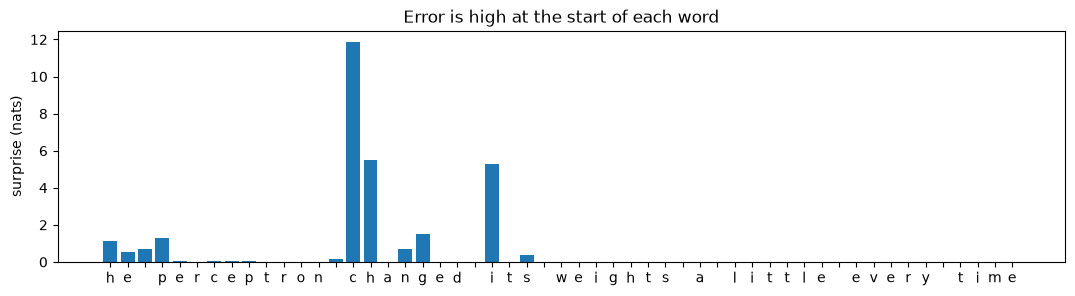

In [4]:
sentence = "the perceptron changed its weights a little every time"
x = torch.tensor([[stoi[c] for c in sentence]], device=device)
model.eval()
with torch.no_grad():
    logits, _ = model(x[:, :-1])
    nll = -F.log_softmax(logits, -1)[0].gather(1, x[0, 1:, None]).squeeze().cpu()
plt.figure(figsize=(13, 3))
plt.bar(range(len(nll)), nll)
plt.xticks(range(len(nll)), list(sentence[1:]))
plt.ylabel("surprise (nats)"); plt.title("Error is high at the start of each word"); plt.show()

## Sampling

In [5]:
def sample(model, prompt, n=300, temperature=0.7):
    x = torch.tensor([[stoi[c] for c in prompt]], device=device)
    with torch.no_grad():
        logits, h = model(x)
        out = prompt
        for _ in range(n):
            p = F.softmax(logits[:, -1] / temperature, -1)
            nxt = torch.multinomial(p, 1)
            out += chars[nxt.item()]
            logits, h = model(nxt, h)
    return out
print(sample(model, "the network "))

the network with hidden layers could learn its own features. convolutional networks learned to read handwritten digits, and recurrent networks learned look at every other word at once. stack enough of these layers, feed them enough text, and they learn grammar, facts, and a surprising amount of reasoning. scali


## Takeaways
- Memory through a feedback loop; trained by BPTT.
- Plain RNNs struggle with **long-range** dependencies because gradients vanish or explode as they pass through many $W_{hh}$ multiplications — the motivation for the LSTM (next notebook).